# 02 · Popularity: which method predicts it best?

**Goal.** Find the method that estimates how much an archived English fiction book is viewed (`views_all_time`) with the highest honest accuracy.

* **Phase 1:** low / medium / high views (thirds of the training books).
* **Phase 2:** the number of views (on a log scale; we also report "within 2x / 3x of the truth").
* **Extra, easier questions** (clearly a different question): *high vs low only* and *top 20% vs the rest*.

**Method comparison.** Feature sets: `base` (book details) and `history` (average views of training books by the same author / with the same subject tags, learned from training books only). Models: Ridge, boosted trees, Random Forest, ExtraTrees, an ensemble, a views-per-year target, and an ordinal version (a number cut into classes).

**Evaluation protocol.** Approximately 15% of items are held out by `work_group`. Methods are selected using 5-fold cross-validation on the training pool. This exploratory notebook also displays held-out results for several variants; these comparisons must not be used to choose the final model or to claim an untouched confirmatory test after further tuning.

*Views measure engagement with one archived copy. The model estimates views of existing books; it does not forecast new books.*

**Review, 22 November 2026.** The final summary now selects the already chosen CV winners, rather than the highest test scores. Its stale output was cleared. Earlier executed outputs are retained; the models were not retrained for this reporting correction. Rerun the notebook in the analysis environment before treating it as the final submission.


In [1]:
import warnings, os
warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")       # be gentle with the laptop
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

SEED = 2026
QUICK = False            # True = smaller/faster run (fewer trees, 3 folds)
N_FOLDS = 3 if QUICK else 5
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 180, "display.max_columns", 40, "display.max_rows", 200)

def find(name):
    """Local repo (notebooks/ or repo root) or, in Google Colab, ask for an upload."""
    for base in [Path("../data"), Path("data"), Path(".")]:
        if (base / name).exists():
            return base / name
    try:
        from google.colab import files
        print("Upload", name); files.upload()
        return Path(name)
    except ImportError:
        raise FileNotFoundError(name + " not found: run from notebooks/ in the repo or put the file next to the notebook")

from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import (HistGradientBoostingRegressor, HistGradientBoostingClassifier,
                              RandomForestRegressor, RandomForestClassifier, ExtraTreesRegressor)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, accuracy_score, f1_score, roc_auc_score, balanced_accuracy_score

NT = 100 if QUICK else 200      # trees in forests

def prep(d):
    d = d.copy()
    d["age_years"] = (pd.to_datetime(d["retrieved_at_utc"], utc=True) - pd.to_datetime(d["addeddate"], utc=True)).dt.days / 365.25
    d["n_creators"] = d["creators"].fillna("").str.count(r"\|") + 1
    d["n_subjects"] = d["subjects"].fillna("").str.count(r"\|") + 1
    d["title_words"] = d["title"].fillna("").str.split().str.len()
    for c in ["genre_science_fiction", "genre_fantasy", "genre_mystery_thriller", "in_americana", "juvenile"]:
        d[c] = d[c].astype(int)
    d["text"] = d["title"].fillna("") + " " + d["subjects"].fillna("").str.replace("|", " ", regex=False)
    d["tags"] = d["subjects"].fillna("").str.split(r" \| ").map(lambda t: [x.strip().lower() for x in t if x.strip()])
    d["author_keys"] = d["first_creator"].fillna("").str.lower().map(lambda a: [a] if a else [])
    d["y"] = np.log1p(d["views_all_time"])
    return d

NUMS = ["publication_year", "scanned_page_count", "age_years", "n_creators", "n_subjects", "title_words",
        "genre_science_fiction", "genre_fantasy", "genre_mystery_thriller", "in_americana", "juvenile"]
df = prep(pd.read_csv(find("training_api.csv"), encoding="utf-8-sig"))
print(df.shape, "| books per sampling group:", df["sampling_stratum"].value_counts().to_dict())

(5600, 37) | books per sampling group: {'science_fiction': 1800, 'fantasy': 1800, 'mystery_thriller': 1800, 'benchmark_random_fiction': 200}


In [2]:
def target_encode(tr, other, keycol, m=5.0, inner=5):
    """Average log-views per key (author or subject tag), smoothed toward the overall mean.
    Training rows get out-of-fold values (grouped by work) so a book never sees its own views; other rows use all training books."""
    ktr, kot, y = tr[keycol].tolist(), other[keycol].tolist(), tr["y"].values
    g = y.mean()
    def stats(idx):
        s, c = {}, {}
        for i in idx:
            for k in ktr[i]:
                s[k] = s.get(k, 0.0) + y[i]; c[k] = c.get(k, 0) + 1
        return s, c
    def enc(keys, s, c):
        vals = [(s[k] + m * g) / (c[k] + m) for k in keys if k in c]
        return (np.mean(vals) if vals else g), sum(c[k] for k in keys if k in c)
    oof = np.zeros((len(tr), 2))
    for a, b in GroupKFold(inner).split(tr, groups=tr["work_group"]):
        s, c = stats(a)
        for i in b: oof[i] = enc(ktr[i], s, c)
    s, c = stats(range(len(tr)))
    return oof, np.array([enc(k, s, c) for k in kot])

def build(tr, te, mode, desc=False):
    Xtr, Xte = tr[NUMS].astype(float).values, te[NUMS].astype(float).values
    if mode == "history":
        for col in ("author_keys", "tags"):
            a, b = target_encode(tr, te, col); Xtr, Xte = np.hstack([Xtr, a]), np.hstack([Xte, b])
    tf = TfidfVectorizer(max_features=200, min_df=5, token_pattern=r"[A-Za-z]{3,}", stop_words="english").fit(tr["text"])
    Xtr, Xte = np.hstack([Xtr, tf.transform(tr["text"]).toarray()]), np.hstack([Xte, tf.transform(te["text"]).toarray()])
    if desc:
        td = TfidfVectorizer(max_features=400, min_df=5, token_pattern=r"[A-Za-z]{3,}", stop_words="english", ngram_range=(1, 2), sublinear_tf=True).fit(tr["description"])
        Xtr, Xte = np.hstack([Xtr, td.transform(tr["description"]).toarray()]), np.hstack([Xte, td.transform(te["description"]).toarray()])
    return Xtr, Xte

def reg_zoo():
    return {
        "Ridge": ("scale", lambda: Ridge(alpha=30)),
        "HGB": ("raw", lambda: HistGradientBoostingRegressor(max_iter=150, learning_rate=0.06, random_state=SEED)),
        "HGB tuned": ("raw", lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.03, max_depth=4, min_samples_leaf=40, l2_regularization=2.0, random_state=SEED)),
        "RandomForest": ("raw", lambda: RandomForestRegressor(n_estimators=NT, min_samples_leaf=5, max_features=0.4, n_jobs=2, random_state=SEED)),
        "ExtraTrees": ("raw", lambda: ExtraTreesRegressor(n_estimators=NT, min_samples_leaf=5, max_features=0.5, n_jobs=2, random_state=SEED)),
    }
def clf_zoo():
    return {
        "LogReg": ("scale", lambda: LogisticRegression(max_iter=3000, C=0.3)),
        "HGB": ("raw", lambda: HistGradientBoostingClassifier(max_iter=150, learning_rate=0.06, random_state=SEED)),
        "RandomForest": ("raw", lambda: RandomForestClassifier(n_estimators=NT, min_samples_leaf=5, max_features=0.4, n_jobs=2, random_state=SEED)),
    }
ENS = ["Ridge", "HGB tuned", "RandomForest"]            # members of the ensemble
def fit_pred(kind, model, Xtr, ytr, Xte, proba=False):
    if kind == "scale":
        sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    model.fit(Xtr, ytr)
    return model.predict(Xte)

cls3 = lambda v, c: np.where(v <= c[0], 0, np.where(v >= c[1], 2, 1))

def run_models(Xtr, ytr_log, vtr, Xte, regs, clfs):
    """Fit everything on one training set; return predictions for Xte."""
    out = {"reg": {}, "clf": {}}
    for k in regs:
        kind, mk = reg_zoo()[k]; out["reg"][k] = fit_pred(kind, mk(), Xtr, ytr_log, Xte)
    mem = [out["reg"][k] for k in ENS if k in out["reg"]]
    if mem: out["reg"]["Ensemble"] = np.mean(mem, axis=0)
    cuts = np.quantile(vtr, [1/3, 2/3])
    for k in clfs:
        kind, mk = clf_zoo()[k]; out["clf"][k] = fit_pred(kind, mk(), Xtr, cls3(vtr, cuts), Xte)
    if "Ensemble" in out["reg"]:
        e = np.quantile(ytr_log, [1/3, 2/3]); est = out["reg"]["Ensemble"]
        out["clf"]["Ordinal (cut the ensemble estimate)"] = np.where(est <= e[0], 0, np.where(est >= e[1], 2, 1))
    return out

def folds(data, n=None):
    return list(StratifiedGroupKFold(n_splits=n or N_FOLDS, shuffle=True, random_state=SEED).split(data, data["sampling_stratum"], data["work_group"]))

def reg_metrics(y, p):
    err = np.abs(p - y)
    return {"R2": r2_score(y, p), "within 2x": float((err <= np.log(2)).mean()), "within 3x": float((err <= np.log(3)).mean()), "Spearman": spearmanr(y, p)[0] if np.std(p) > 0 else 0.0}
def clf_metrics(t, p):
    return {"accuracy": accuracy_score(t, p), "macro-F1": f1_score(t, p, average="macro"), "off by <= 1 class": float((np.abs(p - t) < 2).mean())}

def cv_all(pool, mode, desc, regs, clfs):
    """5-fold grouped cross-validation. Returns out-of-fold predictions and the per-row truth under each fold's own cut-offs."""
    y, v = pool["y"].values, pool["views_all_time"].values
    R = {}; C = {}; truth = np.zeros(len(pool), int); top = np.zeros(len(pool), bool); mid = np.zeros(len(pool))
    for tr_i, te_i in folds(pool):
        tr, te = pool.iloc[tr_i].reset_index(drop=True), pool.iloc[te_i].reset_index(drop=True)
        Xtr, Xte = build(tr, te, mode, desc)
        o = run_models(Xtr, y[tr_i], v[tr_i], Xte, regs, clfs)
        for k, p in o["reg"].items(): R.setdefault(k, np.zeros(len(pool)))[te_i] = p
        for k, p in o["clf"].items(): C.setdefault(k, np.zeros(len(pool), int))[te_i] = p
        cuts = np.quantile(v[tr_i], [1/3, 2/3]); truth[te_i] = cls3(v[te_i], cuts)
        e = np.quantile(y[tr_i], [1/3, 2/3]); mid[te_i] = (e[0] + e[1]) / 2
        top[te_i] = y[te_i] >= np.quantile(y[tr_i], 0.8)
    return R, C, truth, top, mid

## 1. Split
15% of the books are locked away for the final test. Everything else is the training pool (compared by 5-fold cross-validation). All copies/volumes of a work stay on the same side.

In [3]:
pi, ti = next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED).split(df, df["sampling_stratum"], df["work_group"]))
pool, test = df.iloc[pi].reset_index(drop=True), df.iloc[ti].reset_index(drop=True)
assert set(pool["work_group"]).isdisjoint(set(test["work_group"]))
print(f"training pool: {len(pool)} books | locked test: {len(test)} books ({len(test)/len(df):.1%})")

training pool: 4805 books | locked test: 795 books (14.2%)


## 2. Compare methods with cross-validation (training pool only)
Two feature sets x several models. `history` = author / subject-tag history from training books only. This is the slow cell (a few minutes).

In [4]:
REGS, CLFS = list(reg_zoo()), list(clf_zoo())
cv = {}
for mode in ("base", "history"):
    cv[mode] = cv_all(pool, mode, False, REGS, CLFS)
    print(mode, "done", flush=True)
y_pool = pool["y"].values
rows = []
for mode in cv:
    R, C, truth, top, mid = cv[mode]
    for k, p in R.items(): rows.append({"features": mode, "model": k, **reg_metrics(y_pool, p)})
cv_reg = pd.DataFrame(rows)
print("PHASE 2 (number of views) - cross-validation"); display(cv_reg.pivot(index="model", columns="features", values="R2").round(3).join(
    cv_reg.pivot(index="model", columns="features", values="within 2x").round(3), lsuffix=" R2", rsuffix=" within2x"))
rows = []
for mode in cv:
    R, C, truth, top, mid = cv[mode]
    for k, p in C.items(): rows.append({"features": mode, "model": k, **clf_metrics(truth, p)})
cv_clf = pd.DataFrame(rows)
print("PHASE 1 (low / medium / high) - cross-validation"); display(cv_clf.pivot(index="model", columns="features", values="accuracy").round(3))

base done


history done


PHASE 2 (number of views) - cross-validation


features,base R2,history R2,base within2x,history within2x
model,,,,
Ensemble,0.364,0.423,0.539,0.581
ExtraTrees,0.354,0.407,0.535,0.570
HGB,0.346,0.406,0.540,0.576
HGB tuned,0.348,0.412,0.529,0.574
RandomForest,0.358,0.415,0.538,0.574
Ridge,0.315,0.370,0.532,0.567


PHASE 1 (low / medium / high) - cross-validation


features,base,history
model,,
HGB,0.542,0.564
LogReg,0.543,0.577
Ordinal (cut the ensemble estimate),0.539,0.569
RandomForest,0.553,0.592


In [5]:
# one extra method: predict log(views / years on archive.org) then add the age back (removes the age effect from the target)
def cv_per_year(pool, mode):
    y = pool["y"].values; oof = np.zeros(len(pool)); lage = np.log1p(pool["age_years"].values)
    for tr_i, te_i in folds(pool):
        tr, te = pool.iloc[tr_i].reset_index(drop=True), pool.iloc[te_i].reset_index(drop=True)
        Xtr, Xte = build(tr, te, mode)
        kind, mk = reg_zoo()["HGB tuned"]; oof[te_i] = fit_pred(kind, mk(), Xtr, y[tr_i] - lage[tr_i], Xte) + lage[te_i]
    return oof
py = cv_per_year(pool, "history")
print("views-per-year target (history features):", {k: round(v, 3) for k, v in reg_metrics(y_pool, py).items()})
print("compare: HGB tuned with history, normal target:", {k: round(v, 3) for k, v in reg_metrics(y_pool, cv["history"][0]["HGB tuned"]).items()})

views-per-year target (history features): {'R2': 0.416, 'within 2x': 0.58, 'within 3x': 0.81, 'Spearman': np.float64(0.664)}
compare: HGB tuned with history, normal target: {'R2': 0.412, 'within 2x': 0.574, 'within 3x': 0.804, 'Spearman': np.float64(0.663)}


## 3. Select by cross-validation and inspect held-out performance


In [6]:
best_reg = cv_reg.sort_values("R2", ascending=False).iloc[0]
best_clf = cv_clf.sort_values("macro-F1", ascending=False).iloc[0]
print("best regression by CV:", best_reg["features"], "+", best_reg["model"], "| R2 =", round(best_reg["R2"], 3))
print("best classifier by CV:", best_clf["features"], "+", best_clf["model"], "| macro-F1 =", round(best_clf["macro-F1"], 3))

v_pool, y_test = pool["views_all_time"].values, test["y"].values
cut_pool = np.quantile(v_pool, [1/3, 2/3]); t_test = cls3(test["views_all_time"].values, cut_pool)
final = {}
for mode in ("base", "history"):
    Xtr, Xte = build(pool, test, mode)
    final[mode] = run_models(Xtr, y_pool, v_pool, Xte, REGS, CLFS)
base_clf = np.full(len(test), np.bincount(cls3(v_pool, cut_pool)).argmax())
print(f"views cut-offs from the training pool: low <= {cut_pool[0]:.0f}, high >= {cut_pool[1]:.0f}")
rows = [{"features": m, "model": k, **reg_metrics(y_test, p)} for m in final for k, p in final[m]["reg"].items()]
test_reg = pd.DataFrame(rows); print("PHASE 2, locked test (R2 | within 2x)")
display(test_reg.pivot(index="model", columns="features", values="R2").round(3).join(test_reg.pivot(index="model", columns="features", values="within 2x").round(3), lsuffix=" R2", rsuffix=" within2x"))
rows = [{"features": m, "model": k, **clf_metrics(t_test, p)} for m in final for k, p in final[m]["clf"].items()]
rows.append({"features": "-", "model": "baseline (always the commonest class)", **clf_metrics(t_test, base_clf)})
test_clf = pd.DataFrame(rows); print("PHASE 1, locked test"); display(test_clf.round(3))

best regression by CV: history + Ensemble | R2 = 0.423
best classifier by CV: history + RandomForest | macro-F1 = 0.586


views cut-offs from the training pool: low <= 86, high >= 253
PHASE 2, locked test (R2 | within 2x)


features,base R2,history R2,base within2x,history within2x
model,,,,
Ensemble,0.333,0.401,0.576,0.611
ExtraTrees,0.308,0.373,0.562,0.589
HGB,0.335,0.382,0.590,0.595
HGB tuned,0.318,0.383,0.567,0.595
RandomForest,0.325,0.381,0.562,0.608
Ridge,0.295,0.370,0.564,0.590


PHASE 1, locked test


,features,model,accuracy,macro-F1,off by <= 1 class
0,base,LogReg,0.550,0.544,0.916
1,base,HGB,0.579,0.575,0.911
2,base,RandomForest,0.556,0.549,0.902
3,base,Ordinal (cut the ensemble estimate),0.558,0.566,0.964
4,history,LogReg,0.580,0.578,0.921
5,history,HGB,0.589,0.587,0.918
6,history,RandomForest,0.595,0.591,0.911
7,history,Ordinal (cut the ensemble estimate),0.592,0.599,0.964
8,-,baseline (always the commonest class),0.301,0.154,0.629


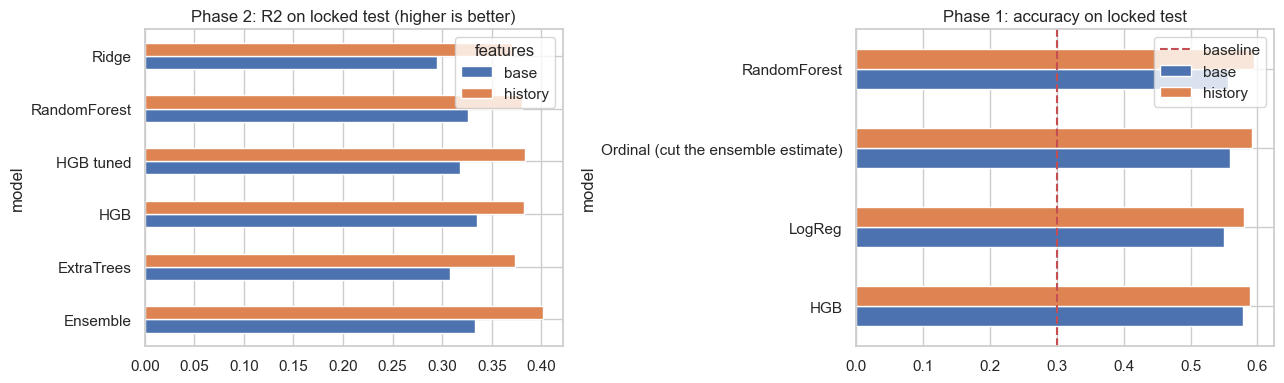

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tr_ = test_reg.pivot(index="model", columns="features", values="R2"); tr_.plot.barh(ax=ax[0]); ax[0].set_title("Phase 2: R2 on locked test (higher is better)")
tc_ = test_clf[test_clf.features != "-"].pivot(index="model", columns="features", values="accuracy"); tc_.plot.barh(ax=ax[1]); ax[1].axvline((base_clf == t_test).mean(), color="r", ls="--", label="baseline")
ax[1].set_title("Phase 1: accuracy on locked test"); ax[1].legend(); plt.tight_layout(); plt.show()

## 4. Easier questions (a different question, not a replacement for Phase 1)
* **High vs low only:** drop the middle third; predict whether a book is in the top or the bottom third.
* **Top 20% vs the rest:** "is this book among the most viewed?"

These are scored from the ensemble's views estimate. The majority-guess baseline is shown, because accuracy alone can look good when one class is large.

In [8]:
def easy_questions(est, y_true_log, v_true, ytr_log, vtr, label):
    cuts = np.quantile(vtr, [1/3, 2/3]); t = cls3(v_true, cuts)
    e = np.quantile(ytr_log, [1/3, 2/3]); thr = (e[0] + e[1]) / 2
    m = t != 1
    hv = {"questions": "high vs low (middle dropped)", "books": int(m.sum()), "accuracy": accuracy_score(t[m] == 2, est[m] > thr),
          "baseline accuracy": max((t[m] == 2).mean(), 1 - (t[m] == 2).mean()), "AUC": roc_auc_score(t[m] == 2, est[m])}
    top = y_true_log >= np.quantile(ytr_log, 0.8)
    pthr = np.quantile(est, 0.8)                                  # flag the 20% with the highest estimate
    t20 = {"questions": "top 20% vs the rest", "books": len(est), "accuracy": accuracy_score(top, est >= pthr),
           "baseline accuracy": 1 - top.mean(), "AUC": roc_auc_score(top, est),
           "precision of flagged top-20%": float(top[est >= pthr].mean())}
    return pd.DataFrame([hv, t20]).assign(where=label)
R, C, truth, top_cv, mid_cv = cv["history"]
est_cv = R["Ensemble"]
# cross-validated version (pooled out-of-fold, per-fold cut-offs are already in `truth`/`top_cv`/`mid_cv`)
m = truth != 1
hv_cv = {"questions": "high vs low (middle dropped)", "books": int(m.sum()), "accuracy": accuracy_score(truth[m] == 2, est_cv[m] > mid_cv[m]),
         "baseline accuracy": max((truth[m] == 2).mean(), 1 - (truth[m] == 2).mean()), "AUC": roc_auc_score(truth[m] == 2, est_cv[m])}
t20_cv = {"questions": "top 20% vs the rest", "books": len(est_cv), "accuracy": accuracy_score(top_cv, est_cv >= np.quantile(est_cv, 0.8)),
          "baseline accuracy": 1 - top_cv.mean(), "AUC": roc_auc_score(top_cv, est_cv)}
display(pd.DataFrame([hv_cv, t20_cv]).assign(where="cross-validation").round(3))
display(easy_questions(final["history"]["reg"]["Ensemble"], y_test, test["views_all_time"].values, y_pool, v_pool, "locked test").round(3))

,questions,books,accuracy,baseline accuracy,AUC,where
0,high vs low (middle dropped),3214,0.829,0.502,0.908,cross-validation
1,top 20% vs the rest,4805,0.809,0.799,0.794,cross-validation


,questions,books,accuracy,baseline accuracy,AUC,precision of flagged top-20%,where
0,high vs low (middle dropped),534,0.798,0.552,0.891,NaN,locked test
1,top 20% vs the rest,795,0.829,0.780,0.806,0.623,locked test


## 5. Results per genre (locked test, best classifier and the ensemble)

In [9]:
ens = final["history"]["reg"]["Ensemble"]; bc = final[best_clf["features"]]["clf"][best_clf["model"]]
rows = []
for g, sub in test.groupby("sampling_stratum"):
    ix = sub.index.values
    rows.append({"group": g, "books": len(ix), "Phase 1 accuracy": accuracy_score(t_test[ix], bc[ix]), "Phase 2 R2": r2_score(y_test[ix], ens[ix]), "within 2x": float((np.abs(ens[ix] - y_test[ix]) <= np.log(2)).mean())})
display(pd.DataFrame(rows).set_index("group").round(3))

,books,Phase 1 accuracy,Phase 2 R2,within 2x
group,,,,
benchmark_random_fiction,35,0.571,0.449,0.486
fantasy,237,0.599,0.391,0.561
mystery_thriller,279,0.645,0.452,0.674
science_fiction,244,0.537,0.276,0.607


## 6. Do descriptions help? (the 3,152 books that have one)
Same books, same split, same features, with and without the description words. Compared by cross-validation and on the locked books of this smaller set.

In [10]:
dd = prep(pd.read_csv(find("training_with_descriptions.csv"), encoding="utf-8-sig")); dd["description"] = dd["description"].fillna("")
pi2, ti2 = next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED).split(dd, dd["sampling_stratum"], dd["work_group"]))
pool2, test2 = dd.iloc[pi2].reset_index(drop=True), dd.iloc[ti2].reset_index(drop=True)
FAST_R, FAST_C = ["Ridge", "HGB tuned"], ["LogReg", "HGB"]
rows = []
for desc in (False, True):
    R2_, C2_, tr2, _, _ = cv_all(pool2, "history", desc, FAST_R, FAST_C)
    y2 = pool2["y"].values
    Xtr, Xte = build(pool2, test2, "history", desc)
    f = run_models(Xtr, y2, pool2["views_all_time"].values, Xte, FAST_R, FAST_C)
    c2 = np.quantile(pool2["views_all_time"].values, [1/3, 2/3]); t2 = cls3(test2["views_all_time"].values, c2)
    rows.append({"description": "with" if desc else "without", "books": len(dd),
                 "CV R2 (ensemble)": reg_metrics(y2, R2_["Ensemble"])["R2"], "CV accuracy (LogReg)": accuracy_score(tr2, C2_["LogReg"]),
                 "TEST R2": reg_metrics(test2["y"].values, f["reg"]["Ensemble"])["R2"], "TEST accuracy (LogReg)": accuracy_score(t2, f["clf"]["LogReg"])})
display(pd.DataFrame(rows).set_index("description").round(3))

,books,CV R2 (ensemble),CV accuracy (LogReg),TEST R2,TEST accuracy (LogReg)
description,,,,,
without,3152,0.377,0.545,0.358,0.577
with,3152,0.354,0.491,0.351,0.508


## 7. Summary

The saved section 3 tables give the CV-selected history RandomForest **59.5% accuracy / 0.591 macro-F1**, against 30.1% baseline accuracy. The CV-selected history Ensemble has **R² 0.401 on log views**, with 61.1% of estimates within a factor of two. These are recorded exploratory results from the 5,600-item snapshot, not results from the ongoing larger collection. The next cell refreshes the summary from the CV-selected rows.


In [ ]:
from IPython.display import Markdown
# Select the test rows for the winners already chosen from training-pool CV.
# Never choose a model by sorting the held-out test scores.
b1 = test_clf[(test_clf["features"] == best_clf["features"]) &
              (test_clf["model"] == best_clf["model"])].iloc[0]
b2 = test_reg[(test_reg["features"] == best_reg["features"]) &
              (test_reg["model"] == best_reg["model"])].iloc[0]
bl = test_clf[test_clf.model.str.startswith("baseline")].iloc[0]["accuracy"]
display(Markdown(f"""
**Held-out results for the methods chosen by training-pool cross-validation.**

* **Phase 1 (low / medium / high):** test accuracy of the CV-selected classifier **{b1['accuracy']:.1%}** ({b1['features']} + {b1['model']}) vs {bl:.1%} for the baseline. Your target of 85% is **{'reached' if b1['accuracy'] >= 0.85 else 'not reached'}**.
* **Phase 2 (views):** test R² of the CV-selected regressor **{b2['R2']:.2f}** ({b2['features']} + {b2['model']}); within 2x of the true views for {b2['within 2x']:.0%} of the books.
* **What helped:** author / subject history features and averaging models (see the tables). Different single models, tuning, a views-per-year target and an ordinal cut gave small or no gains. Descriptions: see section 6.
* **Why it stops here:** popularity depends on things this data does not contain (reading lists, famous authors, links from other sites). Years on archive.org is the strongest input, so the model estimates views of existing books, not future ones.
* **Easier questions** (section 4) reach higher numbers because they are easier questions; report them as such.
"""))